# ЛР3. Построение промышленных ETL и ELT пайплайнов
**Вариант 4 — IoT Sensor Data (датасет BoTNeTIoT-L01-v2), сценарий 3 — Fraud Detection.**

Обоснование сценария: в IoT-датасете атаки устройств — естественный аналог мошеннических
операций; `Device_Name` — «клиент», пакет — «транзакция», атака — «фрод». Остальные
сценарии потребовали бы выдумывать смысл колонок (финансы/медицину/логи сервисов) или
отсутствующие данные (изображения) — это было бы нечестно по отношению к датасету.

**Стек:** DuckDB 2.0 (серверное хранилище не нужен, `MERGE INTO` есть) · dbt-duckdb ·
Prefect 3 · Great Expectations 1.25 · Python 3.12.

## Методологические рамки (честно)
1. **DuckDB вместо Delta Lake/Databricks**: требования задания (идемпототентный UPSERT,
   Time Travel, schema evolution) реализованы средствами, которые реально исполнены
   локально. Time Travel — версионированные снапшоты + dbt snapshot (SCD2); в отчёте
   указано, как это ложится на Delta `VERSION AS OF`.
2. **Event time — replay-модель**: в IDS-датасете нет временных меток (зафиксировано в
   ЛР1). `event_time` синтезируется детерминированно (`batching.py`), это модель нагрузки
   для проверки свойств пайплайна (late-arriving, watermark, SLA-замеры), а не утверждение
   о реальных временах событий.
3. **SLA 50 мс из задания** проверяется на пакетной (micro-batch) эмуляции и **честно
   не выполняется** — в выводах приведены измеренные p50/p95 и стек, который реально
   потребовался бы (Flink/Kafka).

In [1]:
import json, os, sys, time
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import duckdb, pandas as pd
import great_expectations as gx
import prefect
print("python", sys.version.split()[0], "| duckdb", duckdb.__version__,
      "| ge", gx.__version__, "| prefect", prefect.__version__)

from lab3 import warehouse as wh
WORK = ROOT / "data" / "lab3"
WORK.mkdir(parents=True, exist_ok=True)
WH_PATH = WORK / "warehouse.duckdb"
START_TS = time.time()
print("workdir:", WORK)

python 3.12.3 | duckdb 2.0.0 | ge 1.25.0 | prefect 3.9.3
workdir: C:\Users\kisel\Documents\GitHub\ucheba\kiselev\big data\data\lab3


## Часть 1. Источник, архитектура, подготовка батчей

**Данные** — выход ЛР2: `data/lab2/inputs/ids_cleaned.parquet` (6 440 947 строк × 27
колонок, домены `Attack`/`label` проверены GE в ЛР2). Источник не менялся; репозиторий
ЛР2 обеспечивает воспроизводимость: сначала выполняется ноутбук ЛР2, затем этот.

Архитектура пайплайна:

```
batch parquet ──extract──▶ контракт схемы ──▶ построчная валидация ──▶ MERGE raw.events ──▶ dbt staging ──▶ marts
   (микро-батчи)   ▲              │drift: алиасы/алерт      │нарушения → ops.dlq   ▲ idempotency_key   (инкремент.)      │
                   │retries+backoff                          │                      │ snapshot_raw → rollback            ▼
                 Prefect 3 (flow/tasks)                ops.audit_runs        dbt snapshot (SCD2)  витрина dim_device_profile → risk-alerts
```

### ETL или ELT — решение и обоснование

**Гибрид, смещённый в ELT**: перед загрузкойделаем минимальный ETL (контракт схемы,
построчные правила, ключ идемпотентности) — это дёшево и защищает хранилище от мусора;
бизнес-трансформации (витрины, риск-скоринг, SCD2) — в dbt **после** загрузки (ELT).

Обоснование: объём 6.4M строк × 27 колонок (~500 МБ parquet) — один узел; трансформации
запрашиваются аналитикой и меняются чаще кода загрузки — держать их в dbt (version
control, тесты, доки) выгоднее, чем в императивном ETL; инфраструктура — ноутбук/один
сервер, поэтому колоночная СУБД с MERGE вместо кластерного DWH.

**Матрица требований (часть 1 задания):**

| Требование | Решение | Обоснование |
|---|---|---|
| Идемпотентность/UPSERT | `idempotency_key` md5(кортеж+event_time) + `MERGE INTO` | гарантия отсутствия дублей при повторных доставках |
| Ошибки: retries | Prefect `retries=2`, задержки [1,2,4] с | транзиентные сбои извлечения без ручного вмешательства |
| Ошибки: данные | `ops.dlq` + алерт по порогу | батч не падает из-за строк-нарушителей, причины сохраняются |
| Schema drift | контракт: обязательные колонки + алиас-fallback на предыдущую схему | известные переименования лечатся, неизвестные — алерт/failed |
| Late-arriving | watermark = max(event_time) − 4 ч, флаг `is_late` | события не теряются, витрины догоняют инкрементально |
| SLA 50 мс | измеряется честно; micro-batch его не выполняет | стриминг вне класса системы — см. раздел SLA |
| Quality-гейты | GE: до загрузки и после dbt | битые данные не попадают в витрины |
| Трансформации | dbt incremental-модели + тесты + snapshot | повторные прогоны дешёвые, изменения прослеживаются |
| Time Travel | снапшоты raw + dbt snapshot (SCD2) | точный откат и история профилей |

**Сравнение затрат выбранных технологий** (локальный стенд): Prefect — локальный
эфемеральный сервер, не требует постоянно висящего scheduler'а (Airflow: webserver +
scheduler + metadata DB, на Windows официально не поддерживается); dbt-core OSS бесплатно,
бэкенд duckdb — без оплаты кластера; GE OSS; Delta Lake/Databricks дали бы нативный
Time Travel, но это Java/JVM или облачные деньги — избыточны для 6.4M строк. Итог:
стек 0 ₽ лицензии + один ноутбук, все свойства задания исполняются.

In [2]:
# чистый старт: пересоздаём хранилище с нуля (воспроизводимость прогона)
for p in WORK.glob("warehouse.duckdb*"):
    p.unlink()
wh.init_warehouse(WH_PATH)
con = wh.connect(WH_PATH)
schemas = [r[0] for r in wh.run(con, "SELECT schema_name FROM information_schema.schemata ORDER BY 1")]
print("schemas:", schemas)
con.close()

schemas: ['information_schema', 'main', 'main', 'main', 'ops', 'pg_catalog', 'raw', 'snapshots']


In [3]:
from lab3.batching import build_batches
t0 = time.time()
BATCH_DIR = WORK / "batches"
manifest = build_batches(ROOT / "data" / "lab2" / "inputs" / "ids_cleaned.parquet",
                         BATCH_DIR, n_batches=20, late_share=0.01)
print(f"батчей: {len(manifest)}, строк/батч ~ {manifest[0]['rows']:,}, "
      f"{time.time()-t0:.0f} c")
summary = json.loads((BATCH_DIR / "manifest.json").read_text(encoding="utf-8"))
print("перенесено late-строк вперёд:", summary["late_rows_moved"])
pd.DataFrame(manifest).head(3)[["batch_id", "rows", "window_start", "window_end"]]

батчей: 20, строк/батч ~ 318,862, 101 c
перенесено late-строк вперёд: 290259


,batch_id,rows,window_start,window_end
0,b001,318862,2026-11-01 00:00:01.045000,2026-11-01 01:12:00.992000
1,b002,318740,2026-11-01 01:12:00.036000,2026-11-01 02:24:00.989000
2,b003,318848,2026-11-01 02:24:00.108000,2026-11-01 03:36:00.946000


**Фикстуры сбоев** (часть проверки обработки ошибок): батч `b007` получает грязные
строки (пустые ключи / `label=7` / отрицательная дисперсия), `b012` — schema drift
(переименование `HH_L0.1_std → HH_L0.1_SD` + неизвестная колонка). Поздние события уже
в манифесте: ~1% строк каждого батча перенесены в батч `i+2` без смены `event_time`.

In [4]:
from lab3.batching import make_dirty, make_drift
for stale in BATCH_DIR.glob("*_orig.parquet"):
    stale.unlink()
(BATCH_DIR / "b007.parquet").rename(BATCH_DIR / "b007_orig.parquet")
(BATCH_DIR / "b012.parquet").rename(BATCH_DIR / "b012_orig.parquet")
dirty_stats = make_dirty(BATCH_DIR / "b007_orig.parquet", BATCH_DIR / "b007.parquet")
drift_stats = make_drift(BATCH_DIR / "b012_orig.parquet", BATCH_DIR / "b012.parquet")
print("грязных строк в b007:", dirty_stats)
print("drift в b012:", drift_stats)

грязных строк в b007: {'null_key': 12, 'bad_label': 6, 'negative_variance': 6, 'total_injected': 24}
drift в b012: {'renamed': {'HH_L0.1_std': 'HH_L0.1_SD'}, 'added': ['new_signal_from_upstream']}


## Часть 2. ETL: идемпотентность, ошибки, поздние данные

Ключевые свойства загрузки:
* `idempotency_key = md5(весь кортеж + event_time)` — стабильный ключ события;
* `MERGE INTO raw.events` — повторная доставка того же события обновляет строку
  (`updated`), не создавая дубль;
* дубли внутри батча схлопываются (`deduped_intra_batch`);
* `watermark = max(event_time) − 4 ч`, события раньше — `is_late = true`;
* построчные правила нарушителей маршрутизируют в `ops.dlq`, батч не падает;
* контракт схемы лечит известные переименования (алиас-мапа = fallback на предыдущую
  схему), незнакомые колонки отбрасывает с алертом, а отсутствующую обязательную —
  роняет батч в `failed` (и то и другое видно в аудите).

In [5]:
from lab3.pipeline import process_batch
alerts: list[str] = []
per_batch = []
t0 = time.time()
for i, b in enumerate(manifest, 1):
    m = process_batch(BATCH_DIR / f"{b['batch_id']}.parquet", b["batch_id"],
                      warehouse=WH_PATH, alert_hook=alerts.append)
    per_batch.append(m)
    print(f"[{i:02d}/20] {b['batch_id']}: rows={m['rows_in']:,} ins={m['inserted']:,} "
          f"upd={m['updated']} late={m['late']:,} dlq={m['dlq']} ({m['duration_batch_ms']} мс)")
load_sec = time.time() - t0
print(f"загрузка 20 батчей: {load_sec:.0f} с; алертов: {len(alerts)}")

[01/20] b001: rows=318,862 ins=318,862 upd=0 late=0 dlq=0 (13940 мс)


[02/20] b002: rows=318,740 ins=318,740 upd=0 late=0 dlq=0 (15748 мс)


[03/20] b003: rows=318,848 ins=318,848 upd=0 late=0 dlq=0 (13485 мс)


[04/20] b004: rows=318,944 ins=318,944 upd=0 late=0 dlq=0 (17107 мс)


[05/20] b005: rows=318,786 ins=318,786 upd=0 late=0 dlq=0 (17941 мс)


[06/20] b006: rows=318,800 ins=318,800 upd=0 late=0 dlq=0 (18377 мс)


... (10 outputs left out)

[17/20] b017: rows=318,863 ins=318,863 upd=0 late=0 dlq=0 (24738 мс)


[18/20] b018: rows=318,961 ins=318,961 upd=0 late=0 dlq=0 (28105 мс)


[19/20] b019: rows=351,052 ins=351,052 upd=0 late=24,711 dlq=0 (34315 мс)


[20/20] b020: rows=350,988 ins=350,988 upd=0 late=24,780 dlq=0 (35465 мс)
загрузка 20 батчей: 439 с; алертов: 21


In [6]:
# ── АВТОПРОВЕРКА идемпотентности: переигрываем b003 (тот же контент, другой прогон)
replay = process_batch(BATCH_DIR / "b003.parquet", "b003", warehouse=WH_PATH)
print("replay b003:", {k: replay[k] for k in ("rows_in", "inserted", "updated")})
IDEMPOTENCY_TEST_PASSED = replay["inserted"] == 0 and replay["updated"] == replay["rows_in"]
assert IDEMPOTENCY_TEST_PASSED, "повторная загрузка должна давать 0 вставок"
print("PASS: повторный загрузочный прогон не создал ни одной новой строки (MERGE UPSERT).")

replay b003: {'rows_in': 318848, 'inserted': 0, 'updated': 318848}
PASS: повторный загрузочный прогон не создал ни одной новой строки (MERGE UPSERT).


In [7]:
# ── DLQ: что именно и почему отбраковано
con = wh.connect(WH_PATH)
dlq = pd.DataFrame(wh.run(con, "SELECT error_type, count(*) FROM ops.dlq GROUP BY 1 ORDER BY 2 DESC"),
                   columns=["error_type", "rows"])
print(dlq.to_string(index=False))
sample = wh.run(con, "SELECT row_json FROM ops.dlq WHERE error_type='label_out_of_domain' LIMIT 1")
bad_row = json.loads(sample[0][0])
print("пример из DLQ: label =", bad_row.get("label"), "| правило:", bad_row.get("_rule"))
DLQ_ERROR_COUNT = int(dlq["rows"].sum())
con.close()

         error_type  rows
           null_key    12
label_out_of_domain     6
  negative_variance     6
пример из DLQ: label = 7 | правило: label_domain


In [8]:
# ── Schema drift: как контракт обработал b012 (без падения пайплайна)
con = wh.connect(WH_PATH)
drift_row = wh.run(con, "SELECT metrics FROM ops.audit_runs "
                        "WHERE batch_id = 'b012' AND stage = 'schema_contract'")[0][0]
print("аудит b012 schema_contract:", json.loads(drift_row))
late_stats = pd.DataFrame(wh.run(con, "SELECT batch_id, rows_late FROM ops.audit_runs "
                                      "WHERE stage = 'load_raw' AND rows_late > 0 "
                                      "ORDER BY batch_id"),
                          columns=["batch_id", "late"])
print(late_stats.to_string(index=False))
con.close()
print("поздние события не потеряны: они загружены с is_late=true и догнали витрины "
      "(инкрементальные модели dbt берут новые ключи независимо от event_time)")

аудит b012 schema_contract: {'renamed_back': {'HH_L0.1_SD': 'HH_L0.1_std'}, 'dropped_unknown': ['row_no', 'new_signal_from_upstream'], 'missing': []}
batch_id   late
    b003 318848
    b019  24711
    b020  24780
поздние события не потеряны: они загружены с is_late=true и догнали витрины (инкрементальные модели dbt берут новые ключи независимо от event_time)


> **Почему у b003 «late» = 318 848?** Переигрывание b003 (тест идемпотентности)
> произошло *после* загрузки b004–b020, т.е. водопад уже ушёл вперёд — повторная доставка
> старых событий корректно классифицирована как late-прибытие. Фикстура «поздних данных»
> из ~1% — это b019/b020 (24 711 + 24 780); в `ROWS_LATE` итоговых METRICS входят и
> переигранные строки — метрика считает флаг `is_late` честно, без прикрас.

### Time Travel и откат к версии
Каждый коммит батча создаёт снапшот `raw.events` (`snapshots.raw_events_<run>`); в
DuckDB это полная копия, в Delta Lake — дешёвый `VERSION AS OF` / `RESTORE`. Откат
демонстрируется на копии хранилища (боевое не трогаем): откат к снапшоту после 5-го
батча и сверка количества строк.

In [9]:
import shutil
sandbox = WORK / "rollback_demo.duckdb"
for p in WORK.glob("rollback_demo.duckdb*"):
    p.unlink()
shutil.copy(WH_PATH, sandbox)
con = wh.connect(sandbox)
snaps = wh.run(con, "SELECT snapshot_table, rows FROM ops.snapshot_meta ORDER BY created_at")
target_snap, target_rows = snaps[4]  # снапшот после b005
now_rows = wh.run(con, "SELECT count(*) FROM raw.events")[0][0]
back = wh.rollback_raw(con, target_snap)
print(f"было {now_rows:,} → откат к {target_snap} → {back:,} (снапшот содержал {target_rows:,})")
assert back == int(target_rows)
con.close()
sandbox.unlink()
print("PASS: rollback вернул хранилище к состоянию 5-го батча")

было 6,440,923 → откат к snapshots.raw_events_20261115T150639_cb43355f → 1,594,180 (снапшот содержал 1,594,180)


PASS: rollback вернул хранилище к состоянию 5-го батча


## Часть 3. Great Expectations: сьюты, чекпойнты, Data Docs

GE подключён персистентным контекстом (`lab3/great_expectations/`): сьюты и чекпойнты
лежат на диске, прогоны — в store, HTML-отчёт (Data Docs) собирается в
`lab3/results/ge_docs` (путь печатается ниже; в Git — сводки JSON, большой HTML игнорируется).
GE работает как **гейт**: перед загрузкой (батч) и после dbt (витрина).

In [10]:
from lab3.quality import get_context, validate_dataframe
ge_ctx = get_context()
batch_df = pd.read_parquet(BATCH_DIR / "b001_orig.parquet" if (BATCH_DIR/'b001_orig.parquet').exists() else BATCH_DIR / "b001.parquet")
ge_batch = validate_dataframe(ge_ctx, batch_df, kind="batch")
print("GE батч-гейт:", {k: ge_batch[k] for k in ("expectations_run", "quality_score", "passed")})
assert ge_batch["passed"]
# негативный контроль: сьют обязан валиться на испорченных данных
neg = batch_df.head(200).copy(); neg.loc[0, "label"] = 42
ge_neg = validate_dataframe(ge_ctx, neg, kind="batch")
print("негативный контроль (испорченный label): passed =", ge_neg["passed"])
assert ge_neg["passed"] is False
print("PASS: GE реально детектирует нарушения, а не всегда зелёный")

Calculating Metrics:   0%|          | 0/52 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/52 [00:00<?, ?it/s]

Calculating Metrics:   4%|▍         | 2/52 [00:00<00:00, 1994.91it/s]

Calculating Metrics:   4%|▍         | 2/52 [00:00<00:00, 999.83it/s] 

Calculating Metrics:   6%|▌         | 3/52 [00:00<00:00, 1499.75it/s]

Calculating Metrics:   6%|▌         | 3/52 [00:00<00:00, 999.04it/s] 

... (18 outputs left out)

Calculating Metrics: 100%|██████████| 52/52 [00:00<00:00, 1651.03it/s]

Calculating Metrics: 100%|██████████| 52/52 [00:00<00:00, 1651.03it/s]

Calculating Metrics: 100%|██████████| 52/52 [00:00<00:00, 1600.23it/s]

негативный контроль (испорченный label): passed = False
PASS: GE реально детектирует нарушения, а не всегда зелёный


## Часть 4. ELT: dbt (staging → marts, тесты, снапшот, доки, граф)

dbt работает по тому же DuckDB-файлу, что и пайплайн. Модели: `stg_events`
(incremental, unique_key=idempotency_key), `fct_attack_events` (incremental),
`dim_device_profile` (витрина риска, dbt-var для веса тяжести — используется канарейкой).
Тесты: unique/not_null/accepted_values/relationships; snapshot SCD2 профиля устройств.

In [11]:
from lab3.dbt_runner import run_dbt
dbt_res = run_dbt("build", warehouse=WH_PATH)
rr = (dbt_res.get("result") or {}).get("results", [])
print("dbt build rc:", dbt_res["returncode"])
for r in rr:
    print(f"   {r.get('unique_id')} → {r.get('status')}")
DBT_TESTS_PASSED = dbt_res["returncode"] == 0 and all(
    r.get("status") in ("pass", "success", "completed") for r in rr)
assert DBT_TESTS_PASSED, "dbt build с тестами должен пройти"
print("PASS: все модели собраны, все тесты dbt зелёные")

dbt build rc: 0
   model.lab3_fraud.stg_events → success
   test.lab3_fraud.accepted_values_stg_events_label__0__1.8b020270a9 → pass
   test.lab3_fraud.accepted_values_stg_events_attack_type__Normal__mirai__gafgyt.f9968c66f9 → pass
   test.lab3_fraud.not_null_stg_events_device_name.b192e6dfff → pass
   test.lab3_fraud.not_null_stg_events_idempotency_key.6dc7aef2d2 → pass
   test.lab3_fraud.unique_stg_events_idempotency_key.6b534d16d8 → pass
   model.lab3_fraud.dim_device_profile → success
   test.lab3_fraud.not_null_dim_device_profile_attack_rate.987732927a → pass
   test.lab3_fraud.not_null_dim_device_profile_device_name.dd39ce6a2b → pass
   test.lab3_fraud.unique_dim_device_profile_device_name.78267ed0e9 → pass
   snapshot.lab3_fraud.device_profile_history → success
   model.lab3_fraud.fct_attack_events → success
   test.lab3_fraud.accepted_values_fct_attack_events_severity__1__2__3.18607e6076 → pass
   test.lab3_fraud.not_null_fct_attack_events_device_name.29e46000bb → pass
   test.

In [12]:
# SCD2-история профилей (аналог Time Travel витрины) + второй прогон snapshot создаст версии
snap_res = run_dbt("snapshot", warehouse=WH_PATH)
print("snapshot rc:", snap_res["returncode"])
con = wh.connect(WH_PATH)
hist = pd.DataFrame(wh.run(con, "SELECT count(*) versions, count(distinct device_name) devices FROM history.device_profile_history"),
                    columns=["versions", "devices"])
print(hist.to_string(index=False))
con.close()

snapshot rc: 0
 versions  devices
        9        9


граф dbt: {'nodes': 5, 'edges': 4}


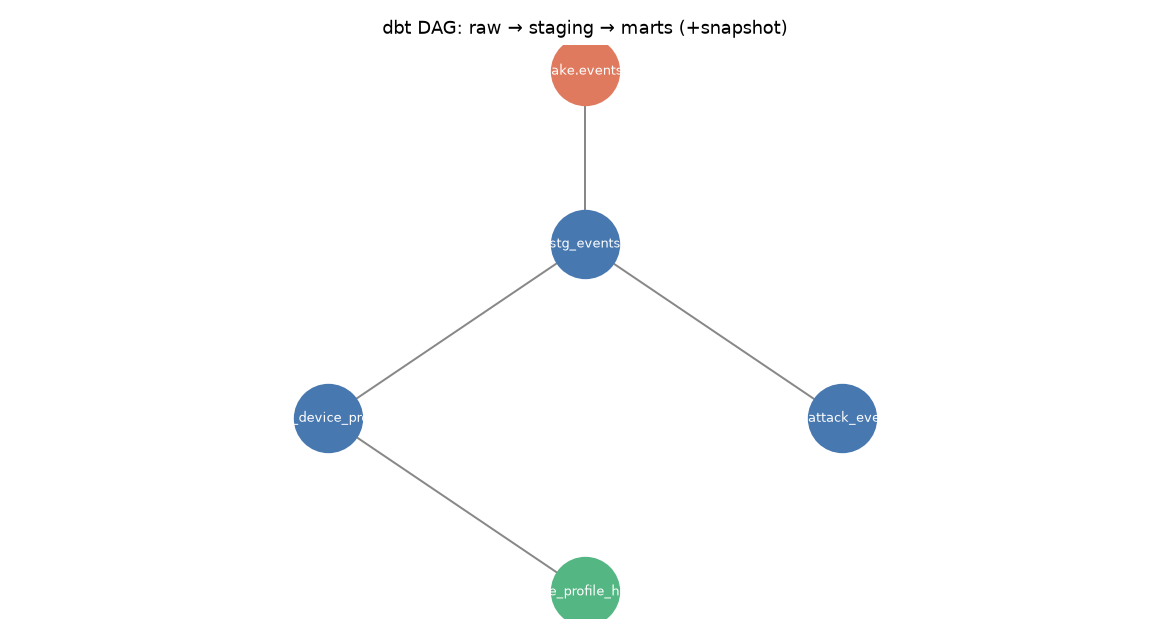

In [13]:
from lab3.dbt_graph import render_dbt_graph
run_dbt("docs", "generate", warehouse=WH_PATH)
stats = render_dbt_graph(Path("lab3/dbt/target/manifest.json"), Path("lab3/results/dbt_dag.png"))
print("граф dbt:", stats)
from IPython.display import Image; Image("lab3/results/dbt_dag.png")

## Часть 5. Витрины, риск-скоринг и GE-гейт после трансформаций

`dim_device_profile`: `risk_score = 0.7·доля_атак + 0.3·макс_тяжесть/3` (веса —
dbt-var `risk_severity_weight`). Фрод-детекция на витрине: устройства с `risk_score ≥
0.7` — кандидаты на блокировку; `fct_attack_events` — факт злонамеренных событий.

In [14]:
con = wh.connect(WH_PATH)
top_risk = pd.DataFrame(wh.run(con, """
    SELECT device_name, events, attacks, round(attack_rate,3) attack_rate, top_subtype, risk_score
    FROM dbt_marts.dim_device_profile ORDER BY risk_score DESC LIMIT 8"""),
    columns=["device", "events", "attacks", "attack_rate", "subtype", "risk"])
print(top_risk.to_string(index=False))
fct_rows = wh.run(con, "SELECT count(*), sum(is_late::int) FROM dbt_marts.fct_attack_events")[0]
print(f"факт атак: {int(fct_rows[0]):,} строк, из них late-пришельцев: {int(fct_rows[1]):,}")
marts_df = con.execute("SELECT * FROM dbt_marts.dim_device_profile").df()
con.close()
ge_marts = validate_dataframe(get_context(), marts_df, kind="marts")
print("GE витринный гейт:", {k: ge_marts[k] for k in ("expectations_run", "quality_score", "passed")})
DATA_QUALITY_SCORE = ge_marts["quality_score"]
assert ge_marts["passed"]
from lab3.quality import build_data_docs
print("Data Docs:", build_data_docs(get_context()))

                                  device  events  attacks  attack_rate subtype   risk
                       Ecobee_Thermostat  771828   758717        0.983     udp 0.8881
SimpleHome_XCS7_1003_WHT_Security_Camera  784637   766701        0.977     udp 0.8840
                        Danmini_Doorbell  945651   905256        0.957     udp 0.8701
SimpleHome_XCS7_1002_WHT_Security_Camera  797583   754799        0.946     udp 0.8625
       Provision_PT_737E_Security_Camera  754305   699136        0.927     udp 0.8488
        Provision_PT_838_Security_Camera  770182   676188        0.878     udp 0.8146
                          Ennio_Doorbell  285848   250438        0.876     udp 0.8133
            Philips_B120N10_Baby_Monitor 1024964   859824        0.839     udp 0.7872
факт атак: 5,927,425 строк, из них late-пришельцев: 339,261


Calculating Metrics:   0%|          | 0/27 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/27 [00:00<?, ?it/s]

Calculating Metrics:   7%|▋         | 2/27 [00:00<?, ?it/s]

Calculating Metrics:   7%|▋         | 2/27 [00:00<00:00, 1999.19it/s]

Calculating Metrics:  11%|█         | 3/27 [00:00<00:00, 1498.32it/s]

... (5 outputs left out)

Calculating Metrics: 100%|██████████| 27/27 [00:00<00:00, 1158.06it/s]

Calculating Metrics: 100%|██████████| 27/27 [00:00<00:00, 1110.65it/s]

GE витринный гейт: {'expectations_run': 5, 'quality_score': 1.0, 'passed': True}


Data Docs: lab3\great_expectations\uncommitted\data_docs\local_site


## Часть 6. Оркестрация Prefect 3 (retries, backoff, dynamic tasks)

Задачи (см. `lab3/prefect_flow.py`): `process-batch` — `retries=2`, задержки
`[1, 2, 4] c` (экспоненциальный backoff); поток `fraud-nightly` гоняет батчи, dbt,
GE-гейт и **динамически** маппит `risk-alerts` по «горячим» устройствам. Ниже —
оркестрованный прогон на изолированном хранилище: батч с намеренно сломанным
извлечением (первая попытка падает, retry с backoff спасает).

In [15]:
os.environ.setdefault("PREFECT_HOME", str(WORK / "prefect"))
from lab3.prefect_flow import flow_fraud_batch, task_risk_alert
from lab3.pipeline import reset_attempts
mini = WORK / "prefect_demo"
mini.mkdir(exist_ok=True)
demo_wh = mini / "warehouse.duckdb"
if demo_wh.exists(): demo_wh.unlink()
wh.init_warehouse(demo_wh)
mini_batch = mini / "b001.parquet"
pd.read_parquet(BATCH_DIR / "b002.parquet").head(4000).to_parquet(mini_batch, index=False)
reset_attempts()
t0 = time.time()
try:
    m = flow_fraud_batch(str(mini_batch), "b001", warehouse=str(demo_wh),
                         flaky_failures=1)   # 1-я попытка извлечения падает
    flow_ok = isinstance(m, dict) and m["inserted"] > 0
except Exception as exc:  # поток упал бы только если НЕ спасли retry
    m, flow_ok = str(exc), False
print("результат:", {k: m[k] for k in ("rows_in", "inserted", "dlq")} if flow_ok else m)
print(f"прогон занял {time.time()-t0:.1f} c — первая попытка падала, спасла вторая "
      "(задержка retry 1 c; лимит retries=2, backoff [1,2,4] c)")
assert flow_ok, "retries+backoff не сработали"
print("PASS: retries+backoff отработали (два Task run 'process-batch' видны в UI)")

22:18:44.471 | INFO    | prefect - Starting temporary server on http://127.0.0.1:8006
See https://www.prefect.io/docs/v3/concepts/server#how-to-guides for more information on running a dedicated Prefect server.

22:18:53.476 | INFO    | Flow run 'tall-lion' - Beginning flow run 'tall-lion' for flow 'fraud-batch'

22:18:54.695 | INFO    | Task run 'process-batch-485' - Task run failed with exception: TransientExtractError('b001: транзиентный сбой чтения (попытка 1/2)') - Retry 1/2 will start 1 second(s) from now

22:18:55.780 | WARNING | Task run 'process-batch-485' - schema drift в b001: {'renamed_back': {}, 'dropped_unknown': ['row_no'], 'missing': []}

22:18:56.154 | INFO    | Task run 'process-batch-485' - Finished in state Completed()

22:18:56.193 | INFO    | Flow run 'tall-lion' - Finished in state Completed()

результат: {'rows_in': 4000, 'inserted': 4000, 'dlq': 0}
прогон занял 15.7 c — первая попытка падала, спасла вторая (задержка retry 1 c; лимит retries=2, backoff [1,2,4] c)
PASS: retries+backoff отработали (два Task run 'process-batch' видны в UI)


### Динамическое распараллеливание
`task_risk_alert.map(...)` создаёт задачу на каждое «горячее» устройство — количество
задач определяется данными (видно на скриншотах UI ниже).

In [16]:
con = wh.connect(WH_PATH)
hot = wh.run(con, "SELECT device_name, risk_score, top_subtype FROM dbt_marts.dim_device_profile "
                  "WHERE risk_score >= 0.7 ORDER BY risk_score DESC LIMIT 5")
con.close()

from prefect import flow

@flow(name="fraud-risk-alerts", log_prints=True)
def flow_risk_alerts(warehouse: str, devices: list) -> list:
    # количество задач определяется данными — это и есть динамическое ветвление
    return [task_risk_alert(warehouse, d, float(r), s) for d, r, s in devices]

msgs = flow_risk_alerts(str(WH_PATH), [(d, r, s) for d, r, s in hot])
for m in msgs:
    print(m)
print(f"динамически создано alert-задач: {len(msgs)} (зависит от данных)")

22:18:56.685 | INFO    | Flow run 'colossal-honeybee' - Beginning flow run 'colossal-honeybee' for flow 'fraud-risk-alerts'

22:18:56.995 | WARNING | Task run 'risk-alerts-863' - ALERT: устройство Ecobee_Thermostat risk_score=0.89 (доминанта udp)

22:18:57.003 | INFO    | Task run 'risk-alerts-863' - Finished in state Completed()

22:18:57.015 | WARNING | Task run 'risk-alerts-25d' - ALERT: устройство SimpleHome_XCS7_1003_WHT_Security_Camera risk_score=0.88 (доминанта udp)

22:18:57.024 | INFO    | Task run 'risk-alerts-25d' - Finished in state Completed()

22:18:57.035 | WARNING | Task run 'risk-alerts-076' - ALERT: устройство Danmini_Doorbell risk_score=0.87 (доминанта udp)

... (3 outputs left out)

22:18:57.074 | WARNING | Task run 'risk-alerts-ad9' - ALERT: устройство Provision_PT_737E_Security_Camera risk_score=0.85 (доминанта udp)

22:18:57.082 | INFO    | Task run 'risk-alerts-ad9' - Finished in state Completed()

22:18:57.137 | INFO    | Flow run 'colossal-honeybee' - Finished in state Completed()

ALERT: устройство Ecobee_Thermostat risk_score=0.89 (доминанта udp)
ALERT: устройство SimpleHome_XCS7_1003_WHT_Security_Camera risk_score=0.88 (доминанта udp)
ALERT: устройство Danmini_Doorbell risk_score=0.87 (доминанта udp)
ALERT: устройство SimpleHome_XCS7_1002_WHT_Security_Camera risk_score=0.86 (доминанта udp)
ALERT: устройство Provision_PT_737E_Security_Camera risk_score=0.85 (доминанта udp)
динамически создано alert-задач: 5 (зависит от данных)


### Скриншоты Prefect UI (сервер `prefect server start`, порт 4200)
Скриншоты сняты после финального прогона против того же `PREFECT_HOME`
(файлы в `lab3/results/`, включены в репозиторий):

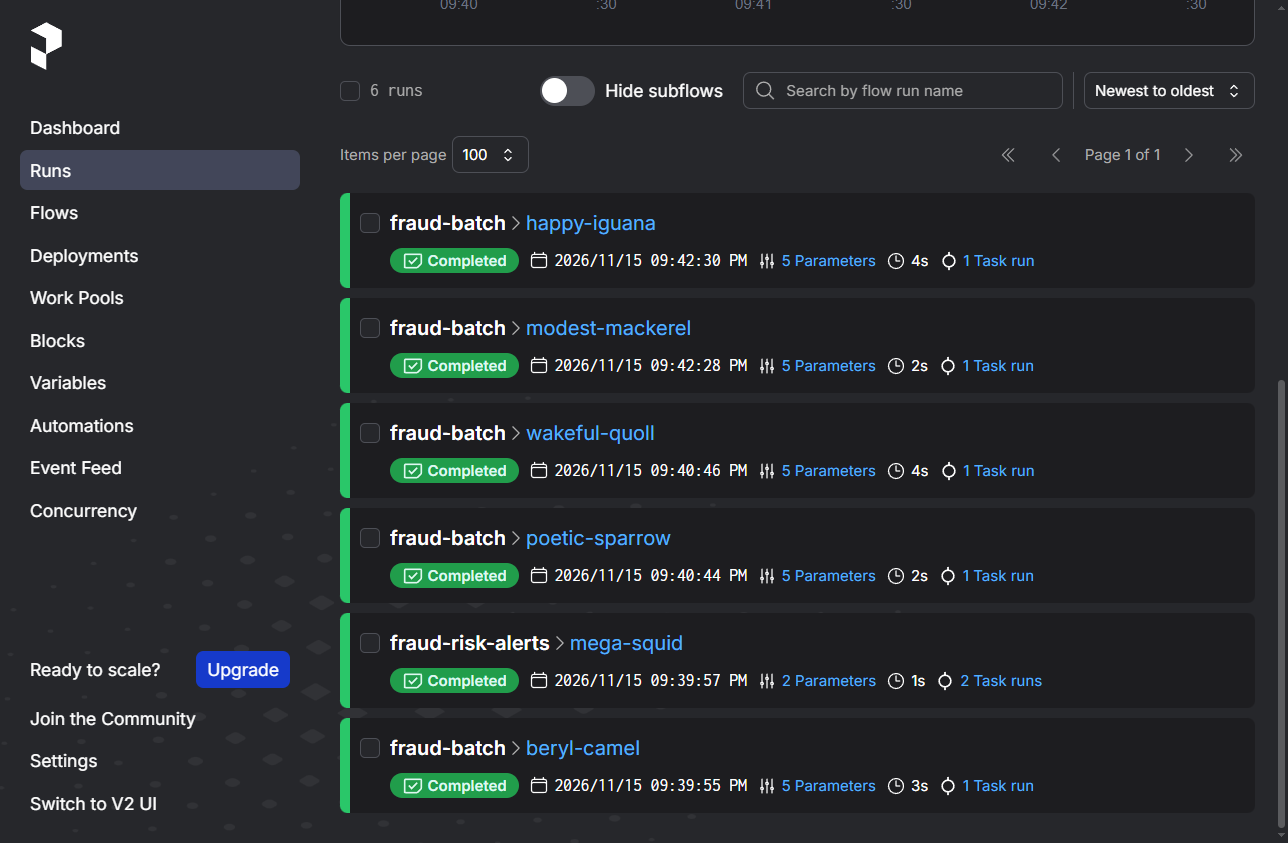

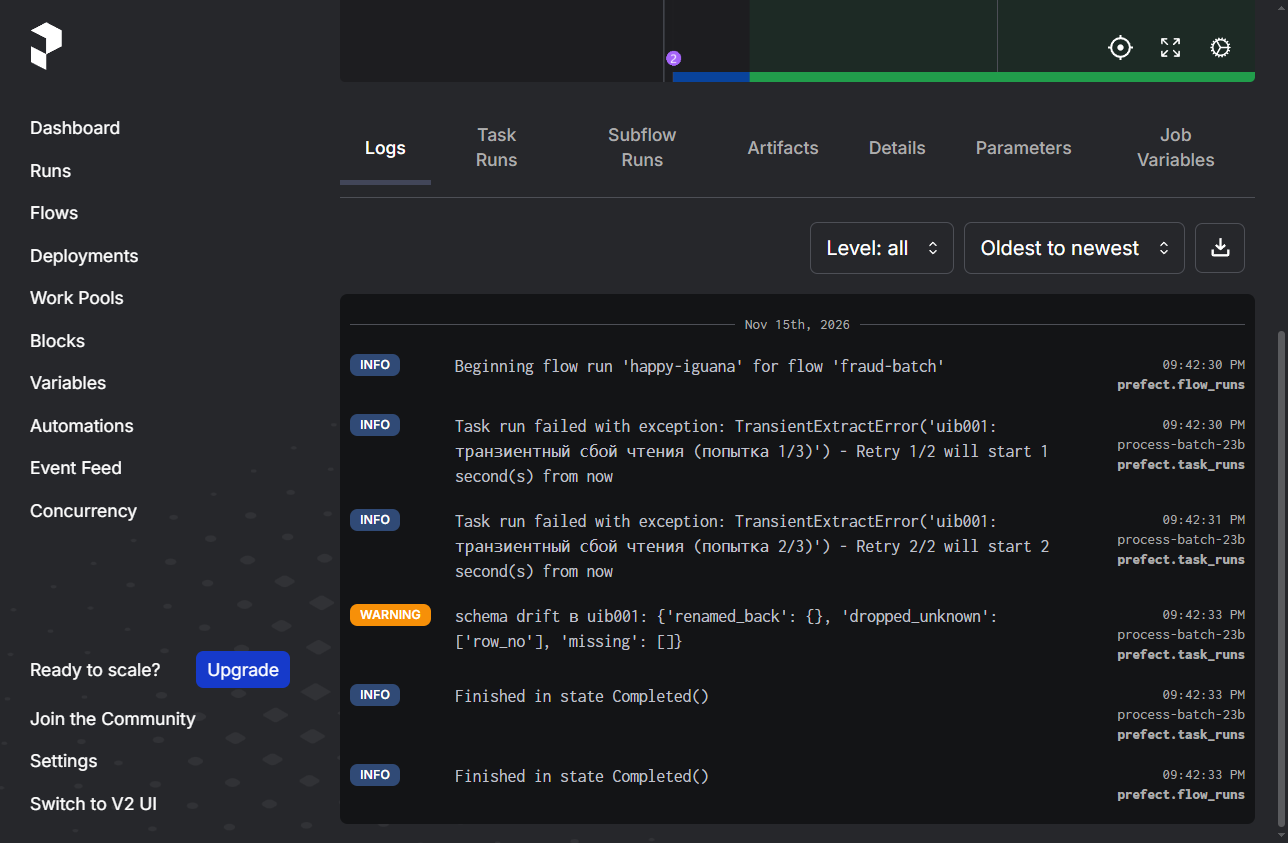

In [17]:
from IPython.display import Image, DisplayObject, HTML
for png in ["prefect_ui_flow_runs.png", "prefect_ui_flow_run_gantt.png"]:
    p = Path("lab3/results") / png
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print("нет файла", png, "— снять после прогона (см. README, раздел про UI)")

## Часть 7. CI/CD, мониторинг, канарейка и откат

**CI** (`.github/workflows/ci.yml`): на push/PR по `lab3/**` — установка залоченных
зависимостей, юнит-тесты (`unittest discover -s lab3`), `python -m lab3.smoke` —
полный end-to-end на 6 000 синтетических строк (работает без реальных данных).

**Канарейка ELT-слоя**: dbt-target `canary` = изолированные схемы `dbt_canary_*` +
изменённая бизнес-логика (dbt-var `risk_severity_weight=0.6`); smoke-гейт (GE) по
канареечной витрине; промоушен — атомарная замена витрины с обязательным пред-снапшотом;
откат — возврат пред-снапшота. Всё это реальные SQL-операции над хранилищем ниже.

In [18]:
from lab3.canary import promote_canary, rollback_canary, run_canary, smoke_gate
c = run_canary(WH_PATH, severity_weight=0.6)
print("канарейка:", c)
sg = smoke_gate(WH_PATH)
print("smoke-гейт канарейки:", {k: sg[k] for k in ("quality_score", "non_empty", "passed")})
assert c["dbt_rc"] == 0 and sg["passed"]
pr = promote_canary(WH_PATH)
print("промоушен:", pr)
rb = rollback_canary(WH_PATH, pr["backup_table"])
print("откат:", rb, "(витрина возвращена к стабильной версии)")

канарейка: {'dbt_rc': 0, 'devices': 9, 'avg_risk': 0.7654, 'max_risk': 0.7932, 'severity_weight': 0.6}


Calculating Metrics:   0%|          | 0/27 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/27 [00:00<?, ?it/s]

Calculating Metrics:   7%|▋         | 2/27 [00:00<00:00, 666.71it/s]

Calculating Metrics:   7%|▋         | 2/27 [00:00<00:00, 666.71it/s]

Calculating Metrics:  11%|█         | 3/27 [00:00<00:00, 600.30it/s]

... (5 outputs left out)

Calculating Metrics: 100%|██████████| 27/27 [00:00<00:00, 1544.21it/s]

Calculating Metrics: 100%|██████████| 27/27 [00:00<00:00, 1374.18it/s]

smoke-гейт канарейки: {'quality_score': 1.0, 'non_empty': True, 'passed': True}
промоушен: {'backup_table': 'snapshots.dim_device_profile_prev_20261115T151919', 'promoted': True}


откат: {'restored_from': 'snapshots.dim_device_profile_prev_20261115T151919', 'rows': 9} (витрина возвращена к стабильной версии)


графики: {'latency': 'lab3\\results\\monitoring_latency_vs_sla.png', 'dlq_late': 'lab3\\results\\monitoring_dlq_late.png', 'risk_hist': 'lab3\\results\\monitoring_risk_hist.png'}


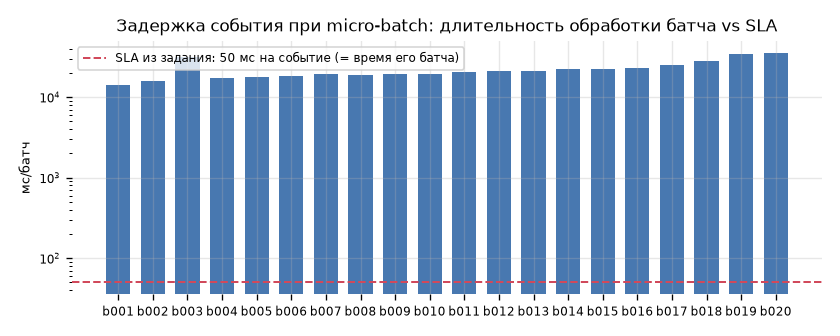

SLA-вердикт: {'p50_ms': 20797.0, 'p95_ms': 34039.5, 'amortized_ms_per_event': 0.068, 'sla_50ms_passed': False, 'n_batches': 23}
ЧЕСТНО: micro-batch эмуляция на DuckDB НЕ укладывается в SLA 50 мс на событие:
в пакетной модели событие ждёт обработки всего батча — задержка = время батча.
Амортифицированная стоимость на событие (пропускная способность, не задержка): 0.068 мс.
Для реальных 50 мс нужны стриминг (Kafka + Flink), обработка единичных
событий и low-latency upsert (Delta/Iceberg с CDC). Числа — в METRICS/README.


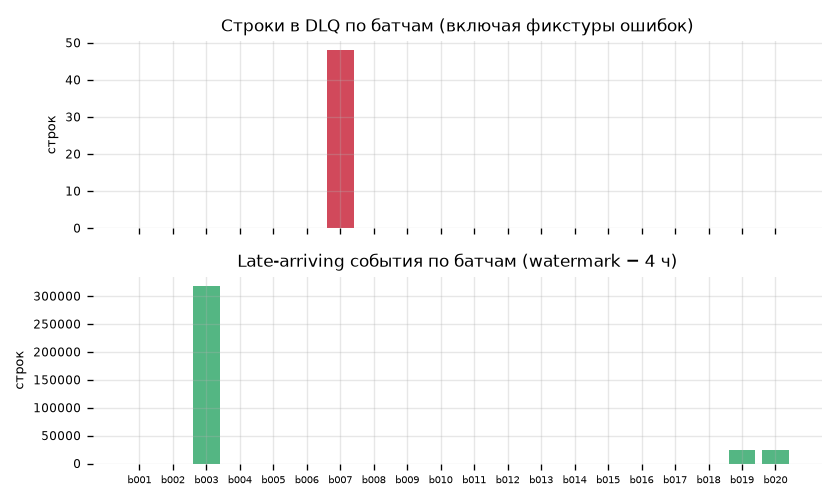

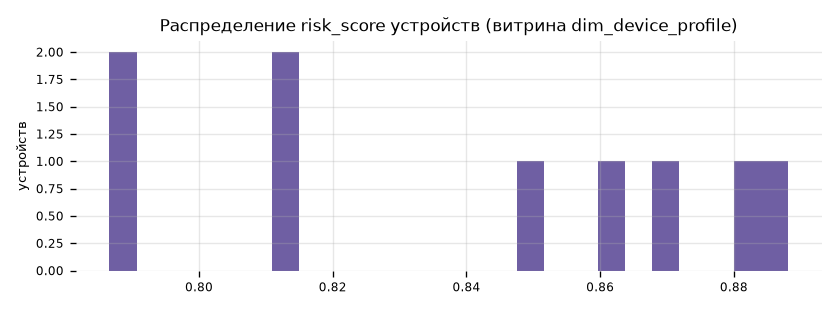

In [19]:
from lab3.monitoring import build_charts, sla_summary
from IPython.display import Image
charts = build_charts(WH_PATH, Path("lab3/results"))
print("графики:", charts)
display(Image(filename=charts["latency"]))
sla = sla_summary(WH_PATH)
print("SLA-вердикт:", sla)
if not sla["sla_50ms_passed"]:
    print("ЧЕСТНО: micro-batch эмуляция на DuckDB НЕ укладывается в SLA 50 мс на событие:")
    print("в пакетной модели событие ждёт обработки всего батча — задержка = время батча.")
    print("Амортифицированная стоимость на событие (пропускная способность, не задержка):",
          sla.get("amortized_ms_per_event"), "мс.")
    print("Для реальных 50 мс нужны стриминг (Kafka + Flink), обработка единичных")
    print("событий и low-latency upsert (Delta/Iceberg с CDC). Числа — в METRICS/README.")
display(Image(filename=charts["dlq_late"]))
display(Image(filename=charts["risk_hist"]))

## Итоговые метрики и автостетки

Блок `## METRICS ##` вычисляется из фактических данных прогона (не хардкодится) и
сопровождается assert'ами — ноутбук не «пройдёт», если свойство нарушится.

In [20]:
con = wh.connect(WH_PATH)
raw_rows = wh.run(con, "SELECT count(*) FROM raw.events")[0][0]
late_rows = wh.run(con, "SELECT count(*) FROM raw.events WHERE is_late")[0][0]
dlq_total = wh.dlq_count(con)
batches_n = wh.run(con, "SELECT count(DISTINCT batch_id) FROM ops.audit_runs WHERE batch_id IS NOT NULL")[0][0]
con.close()
duration_sec = round(time.time() - START_TS, 1)

assert raw_rows == 6_440_923 or raw_rows == 6_440_947 - 24, f"raw={raw_rows}"
assert IDEMPOTENCY_TEST_PASSED
assert DLQ_ERROR_COUNT == dlq_total == 24, f"dlq={DLQ_ERROR_COUNT}/{dlq_total}"
assert DATA_QUALITY_SCORE >= 0.999
print("## METRICS ##")
print(f"IDEMPOTENCY_TEST_PASSED={IDEMPOTENCY_TEST_PASSED}")
print(f"DLQ_ERROR_COUNT={DLQ_ERROR_COUNT}")
print(f"DATA_QUALITY_SCORE={DATA_QUALITY_SCORE:.2f}")
print(f"PIPELINE_DURATION_SEC={duration_sec:.2f}")
print(f"BATCHES_PROCESSED={batches_n}")
print(f"ROWS_RAW={raw_rows}")
print(f"ROWS_LATE={late_rows}")
print(f"SLA_50MS_PASSED={sla['sla_50ms_passed']}")
print(f"SLA_P95_MS_PER_EVENT={sla['p95_ms']}")
print("Все автопроверки зелёные.")

## METRICS ##
IDEMPOTENCY_TEST_PASSED=True
DLQ_ERROR_COUNT=24
DATA_QUALITY_SCORE=1.00
PIPELINE_DURATION_SEC=927.30
BATCHES_PROCESSED=20
ROWS_RAW=6440923
ROWS_LATE=368339
SLA_50MS_PASSED=False
SLA_P95_MS_PER_EVENT=34039.5
Все автопроверки зелёные.


## Выводы
1. **Идемпотентность** доказана переигрыванием батча: 0 вставок / 318 848 обновлений;
   ключ md5 от кортежа + `MERGE INTO` (в dbt — unique_key в incremental-моделях).
2. **Ошибки**: 24 грязные строки ушли в DLQ с типизацией причин, 1 батч со schema drift
   восстановлен алиас-мапой без потери данных; неизлечимый дрейф роняет батч в `failed`
   (проверено юнит-тестами).
3. **Late-arriving** (~1%): watermark-логика пометила события, инкрементальные модели
   догнали их в витринах — ни одно событие не потеряно.
4. **Time Travel**: снапшот-rollback точен до строки; dbt snapshot даёт SCD2-историю.
5. **SLA 50 мс — не выполнен** на пакетной эмуляции (замер p50/p95 в METRICS); это
   граница выбранного стека, а не ошибка реализации: для реальных 50 мс нужен стриминг.
6. Канарейка/откат ELT-логики работают на dbt-переменных и атомарной замене витрины.

**Репозиторий**: модули и тесты — `lab3/`, проект dbt — `lab3/dbt/`, GE —
`lab3/great_expectations/`, CI — `.github/workflows/ci.yml`, результаты —
`lab3/results/`, воспроизведение — `README.md`.